# Renormalizing S-parameters 

This example demonstrates how to use skrf to renormalize a Network's s-parameters to new port impedances. Although trivial, this example creates a matched load in 50ohms and then re-normalizes to a  25ohm environment, producing a reflection coefficient of 1/3.

## Ok lets do it

In [1]:
import skrf as rf
from skrf.instances import wr10

%matplotlib inline

rf.stylely()

# this is just for plotting junk
kw = dict(draw_labels=True, marker = 'o', markersize = 10)

Create a one-port ideal match Network, (using the premade media class wr10 as a dummy)

In [2]:
match_at_50 = wr10.match()

Note that the z0 for this Network defaults to a constant 50ohm

In [3]:
match_at_50

1-Port Network: '',  75.0-110.0 GHz, 1001 pts, z0=[50.+0.j]

Plotting its reflection coefficient on the smith chart, shows its a match

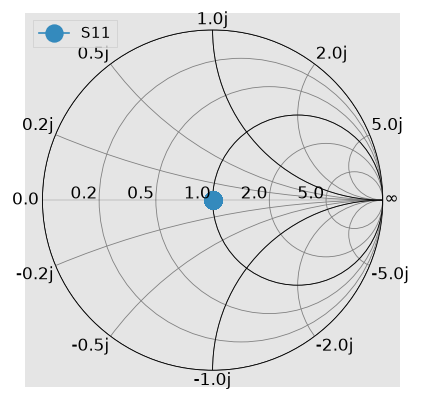

In [4]:
match_at_50.plot_s_smith(**kw)

Now, renormalize the port impedance from 50 -> 25, thus the previous 50ohm load now produces a reflection coefficient of 


$$ \Gamma^{'} = \frac{50-25}{50+25} = \frac{25}{75} = .333 $$


Plotting the renormalized response  on the Smith Chart

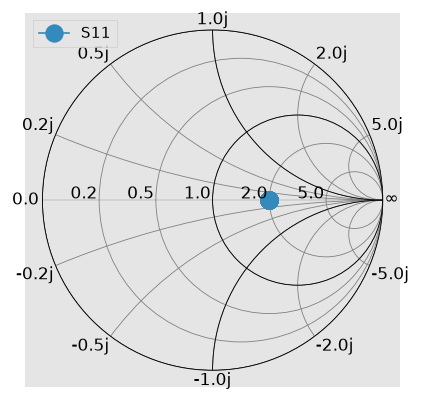

In [5]:
match_at_50.renormalize(25)
match_at_50.plot_s_smith(**kw)

## Complex Impedances 

You could also renormalize to a complex port impedance if you're crazy. For example, renormalizing to 50j, one would expect:
$$
\Gamma^{'} = \frac{50-50j}{50+50j} = 50\frac{1-j}{1+j} = -50j
$$

However, one finds an unexpected result when plotting the Smith chart:

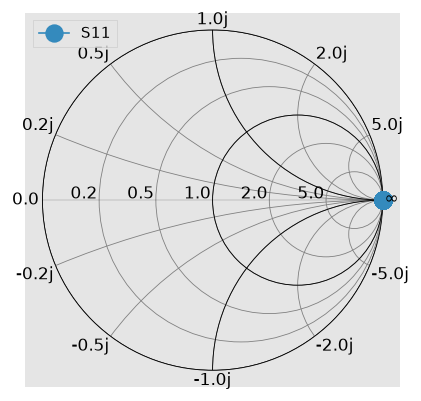

In [6]:
match_at_50 = wr10.match()
match_at_50.renormalize(50j)  # same as renormalize(50j, s_def='power')
match_at_50.plot_s_smith(**kw)  # expect -1j

This is because the default behaviour of scikit-rf is to use _power-waves_ scattering parameter definition (since it is the most popular one is CAD software). But the _power-waves_ definition is [known to fail in such a case](https://www.nist.gov/system/files/documents/2017/05/09/MicrowaveCircuitTheory-proof.pdf). This is why scikit-rf also implement the _pseudo-waves_ scattering parameters definition, but you have to specify it using the `s_def` parameter:  

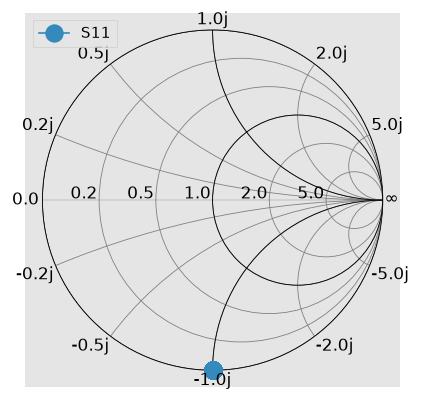

In [7]:
match_at_50 = wr10.match()
match_at_50.renormalize(50j, s_def='pseudo')
match_at_50.plot_s_smith(**kw)  # expect -1j

Which gives the expected result. 